# Portfolio Optimizer: Markowitz vs. 1/N out-of-sample

## Fragestellung
Schlägt ein Mean-Variance-optimiertes Portfolio die naive 1/N-Gewichtung, wenn
Erwartungsrendite und Kovarianz nur aus historischen Daten geschätzt werden?
Verbessert Covariance Shrinkage (Ledoit-Wolf) das Ergebnis?

## Hypothese
Schätzfehler in μ und Σ dominieren den theoretischen Vorteil der Optimierung.
Markowitz verliert daher out-of-sample häufig gegen 1/N, Shrinkage mildert das.

## Design
- Universum: 8 liquide ETFs (Aktien, Anleihen, Gold, Rohstoffe, Immobilien)
- Rollierendes Schätzfenster, monatliches Rebalancing, long-only
- Vergleich: 1/N, Min-Varianz, Max-Sharpe, Min-Varianz mit Ledoit-Wolf
- Kennzahlen: Sharpe Ratio, Volatilität, Max-Drawdown, Turnover

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import cvxpy as cp
import os

In [2]:
tickers = ["SPY", "EFA", "EEM", "TLT", "IEF", "GLD", "DBC", "VNQ"]

prices = yf.download(
    tickers, start="2007-01-01", auto_adjust=True, progress=False
)["Close"].dropna()

os.makedirs("../data", exist_ok=True)
prices.to_csv("../data/prices.csv")

rets = prices.pct_change().dropna()   # einfache Renditen

print(prices.index[0].date(), "bis", prices.index[-1].date(), prices.shape)

summary = pd.DataFrame({
    "Rendite p.a.": rets.mean() * 252,
    "Vola p.a.": rets.std() * np.sqrt(252),
})
summary["Sharpe (ohne Zins)"] = summary["Rendite p.a."] / summary["Vola p.a."]
summary.round(3)

/Users/leokonig/Documents/quant-portfolio-optimizer/.venv/lib/python3.11/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/leokonig/Documents/quant-portfolio-optimizer/.venv/lib/python3.11/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/leokonig/Documents/quant-portfolio-optimizer/.venv/lib/python3.11/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

2007-01-03 bis 2026-10-26 (4985, 8)


/Users/leokonig/Documents/quant-portfolio-optimizer/.venv/lib/python3.11/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Users/leokonig/Documents/quant-portfolio-optimizer/.venv/lib/python3.11/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


,Rendite p.a.,Vola p.a.,Sharpe (ohne Zins)
Ticker,,,
DBC,0.047,0.193,0.243
EEM,0.083,0.280,0.298
EFA,0.070,0.216,0.323
GLD,0.106,0.182,0.585
IEF,0.033,0.069,0.477
SPY,0.123,0.195,0.628
TLT,0.038,0.150,0.255
VNQ,0.094,0.294,0.321


## Mathematische Formulierung

**Notation.** $n=8$ Assets, Gewichte $w\in\mathbb{R}^n$, einfache Renditen $r_t$, $\mu=\mathbb{E}[r]$, $\Sigma=\mathrm{Cov}(r)$. Portfoliorendite $\mu^\top w$, Portfoliovarianz $w^\top\Sigma w$.

**Minimum-Varianz-Portfolio (long-only)**
$$\min_{w}\; w^\top\Sigma w \quad \text{s.t.}\quad \mathbf 1^\top w=1,\; w\ge 0$$

**Efficient Frontier.** Wie oben, zusätzlich $\mu^\top w\ge r^*$; die Zielrendite $r^*$ wird variiert.

**Maximum-Sharpe-Portfolio.** Das Problem
$$\max_{w}\; \frac{\mu^\top w-r_f}{\sqrt{w^\top\Sigma w}}$$
ist in dieser Form nicht konvex. Mit der Substitution $y=w/c$, $c=(\mu-r_f\mathbf 1)^\top w>0$, gilt $\mathrm{Sharpe}=1/\sqrt{y^\top\Sigma y}$. Maximieren heißt also minimieren:
$$\min_{y}\; y^\top\Sigma y \quad \text{s.t.}\quad (\mu-r_f\mathbf 1)^\top y=1,\; y\ge 0,\qquad w=\frac{y}{\mathbf 1^\top y}$$
Das ist ein konvexes quadratisches Programm.

**Schätzfehler.** Der Standardfehler des Mittelwerts ist etwa $\sigma/\sqrt{T}$ (T in Jahren). Bei $\sigma\approx 0.2$ und $T=5$ sind das etwa 9 Prozentpunkte, mehr als die Renditeunterschiede zwischen den Assets. Der Optimizer überschätzt systematisch genau die Assets mit positivem Schätzfehler. Für $\Sigma$ müssen $n(n+1)/2=36$ Parameter geschätzt werden.

**Covariance Shrinkage (Ledoit-Wolf).**
$$\hat\Sigma_{LW}=(1-\delta)\,S+\delta\,\frac{\mathrm{tr}(S)}{n}\,I,\qquad \delta\in[0,1]\ \text{datengetrieben}$$

**Kennzahlen.** Sharpe $=\frac{\bar r_p-r_f}{\sigma_p}$ (annualisiert), Max-Drawdown $=\min_t\left(\frac{V_t}{\max_{s\le t}V_s}-1\right)$, Turnover $=\sum_i|w_i^{neu}-w_i^{alt}|$ je Rebalancing.

**Backtest-Design.** Zum Monatsende $t$ werden $\mu,\Sigma$ nur aus Daten bis $t$ geschätzt, die Gewichte gelten im Folgemonat (kein Look-ahead). Das Schätzfenster legen wir später fest.

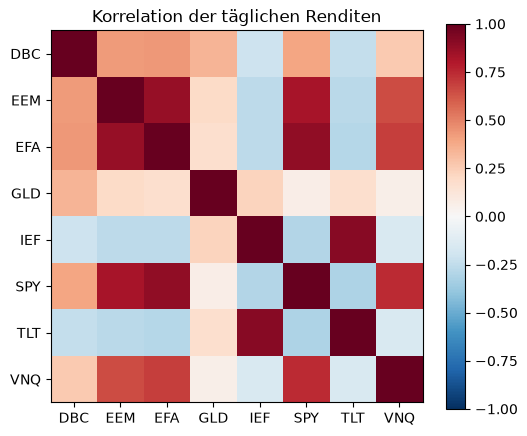

In [3]:
rets = prices.pct_change().dropna()      # einfache Renditen
mu = rets.mean() * 252
Sigma = rets.cov() * 252

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(rets.corr(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rets.columns)), rets.columns)
ax.set_yticks(range(len(rets.columns)), rets.columns)
fig.colorbar(im)
ax.set_title("Korrelation der täglichen Renditen")
plt.show()

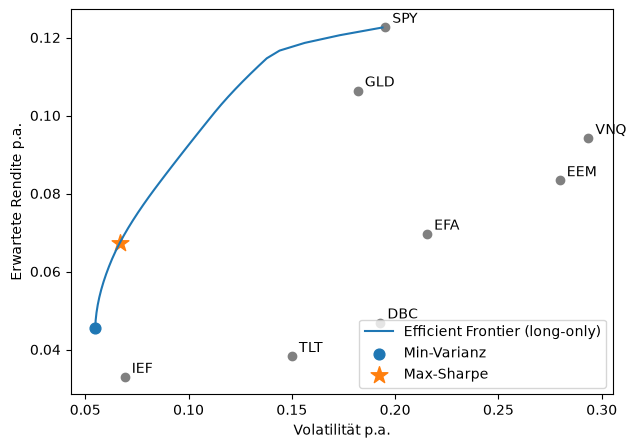

,Min-Varianz,Max-Sharpe
Ticker,,
DBC,0.089,0.000
EEM,0.000,0.000
EFA,0.000,0.000
GLD,-0.000,0.144
IEF,0.785,0.591
SPY,0.126,0.265
TLT,-0.000,-0.000
VNQ,0.000,0.000


In [4]:
import cvxpy as cp

def min_variance(S):
    w = cp.Variable(len(S))
    cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(S))),
               [cp.sum(w) == 1, w >= 0]).solve()
    return w.value

def target_return(m, S, target):
    w = cp.Variable(len(S))
    cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(S))),
               [cp.sum(w) == 1, w >= 0, m @ w >= target]).solve()
    return w.value

def max_sharpe(m, S, rf=0.0):
    y = cp.Variable(len(S))
    cp.Problem(cp.Minimize(cp.quad_form(y, cp.psd_wrap(S))),
               [(m - rf) @ y == 1, y >= 0]).solve()
    return y.value / y.value.sum()

m, S = mu.values, Sigma.values
S = (S + S.T) / 2                         # numerisch symmetrisch
vol = lambda w: np.sqrt(w @ S @ w)

w_mv, w_ms = min_variance(S), max_sharpe(m, S)
targets = np.linspace(m @ w_mv, m.max() * 0.999, 40)
front = np.array([(vol(w), m @ w) for w in (target_return(m, S, t) for t in targets)])

plt.figure(figsize=(7, 5))
plt.plot(front[:, 0], front[:, 1], label="Efficient Frontier (long-only)")
plt.scatter(np.sqrt(np.diag(S)), m, color="grey")
for name, x, y in zip(mu.index, np.sqrt(np.diag(S)), m):
    plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 3))
plt.scatter(vol(w_mv), m @ w_mv, s=60, label="Min-Varianz")
plt.scatter(vol(w_ms), m @ w_ms, marker="*", s=160, label="Max-Sharpe")
plt.xlabel("Volatilität p.a."); plt.ylabel("Erwartete Rendite p.a.")
plt.legend(); plt.show()

pd.DataFrame({"Min-Varianz": w_mv, "Max-Sharpe": w_ms}, index=mu.index).round(3)

## Out-of-sample-Backtest

**Regeln (vor dem Lauf festgelegt)**
- Rebalancing zum Monatsende, Gewichte gelten im Folgemonat
- Schätzfenster: 1260 Handelstage (ca. 5 Jahre), nur Daten bis zum Rebalancing-Tag
- Long-only, keine Transaktionskosten, risikofreier Zins = 0
- Strategien: 1/N, Min-Varianz, Min-Varianz mit Ledoit-Wolf, Max-Sharpe, Max-Sharpe mit Ledoit-Wolf; Benchmark: SPY

**Erwartung vor dem Lauf**
1. Max-Sharpe hat deutlich höheren Turnover und instabilere Gewichte als Min-Varianz, weil $\mu$ schlecht schätzbar ist.
2. Min-Varianz kommt ohne Schätzung von $\mu$ aus und sollte robuster sein.
3. Ledoit-Wolf verbessert die Stabilität, aber nicht zwingend den Sharpe.
4. Max-Sharpe schlägt 1/N nicht eindeutig.

In [5]:
from sklearn.covariance import LedoitWolf

WINDOW = 1260   # ca. 5 Jahre Handelstage
sym = lambda S: (S + S.T) / 2

strategies = {
    "1/N":              lambda est: np.ones(est.shape[1]) / est.shape[1],
    "Min-Varianz":      lambda est: min_variance(sym(est.cov().values * 252)),
    "Min-Varianz (LW)": lambda est: min_variance(sym(LedoitWolf().fit(est).covariance_ * 252)),
    "Max-Sharpe":       lambda est: max_sharpe(est.mean().values * 252, sym(est.cov().values * 252)),
    "Max-Sharpe (LW)":  lambda est: max_sharpe(est.mean().values * 252, sym(LedoitWolf().fit(est).covariance_ * 252)),
}

def month_returns(r_month, w):
    """Tägliche Portfoliorenditen im Monat, Gewichte driften frei (Buy & Hold)."""
    value = (1 + r_month).cumprod() @ w          # Portfoliowert, Start = 1
    return value.pct_change().fillna(value.iloc[0] - 1)

me = rets.groupby(rets.index.to_period("M")).tail(1).index   # Monatsend-Handelstage
port = {k: [] for k in strategies}
weights = {k: [] for k in strategies}
last_w = {k: np.ones(rets.shape[1]) / rets.shape[1] for k in strategies}

for t, t_next in zip(me[:-1], me[1:]):
    loc = rets.index.get_loc(t)
    if loc + 1 < WINDOW:
        continue
    est = rets.iloc[loc + 1 - WINDOW: loc + 1]                    # nur Daten bis t
    nxt = rets.loc[(rets.index > t) & (rets.index <= t_next)]     # Folgemonat
    for k, f in strategies.items():
        try:
            w = np.clip(f(est), 0, None)
            w = w / w.sum()
        except Exception:
            w = last_w[k]                                         # Solver-Fehler: alte Gewichte
        weights[k].append(pd.Series(w, index=rets.columns, name=t))
        port[k].append(month_returns(nxt, w))
        last_w[k] = w

bt = pd.DataFrame({k: pd.concat(v) for k, v in port.items()})
bt["SPY (Buy&Hold)"] = rets["SPY"].loc[bt.index]
print(bt.index[0].date(), "bis", bt.index[-1].date(), len(bt), "Handelstage")

2012-02-01 bis 2026-10-26 3705 Handelstage


,Rendite p.a. (geom.),Vola p.a.,Sharpe,Max-Drawdown,Turnover/Monat
1/N,0.061,0.096,0.658,-0.207,0.000
Min-Varianz,0.034,0.052,0.656,-0.173,0.010
Min-Varianz (LW),0.035,0.053,0.686,-0.168,0.010
Max-Sharpe,0.075,0.089,0.854,-0.201,0.136
Max-Sharpe (LW),0.078,0.091,0.868,-0.208,0.124
SPY (Buy&Hold),0.147,0.165,0.914,-0.337,NaN


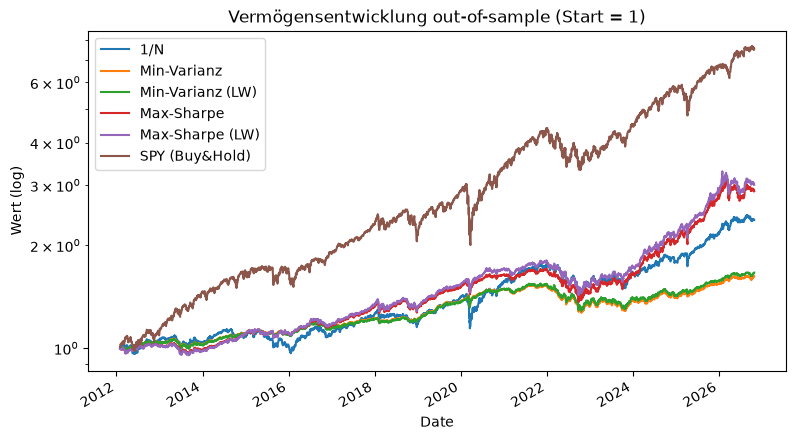

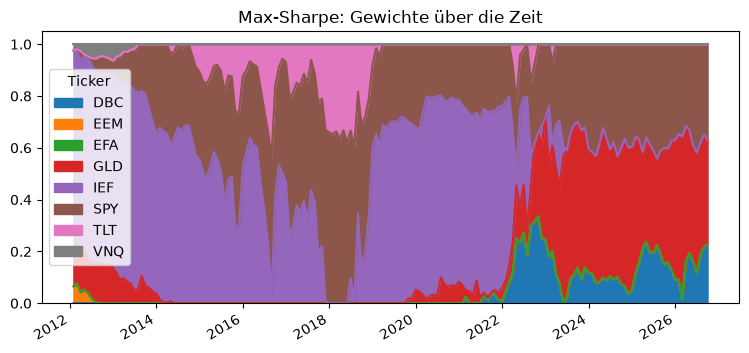

In [6]:
def metrics(r):
    wealth = (1 + r).cumprod()
    vol = r.std() * np.sqrt(252)
    return pd.Series({
        "Rendite p.a. (geom.)": wealth.iloc[-1] ** (252 / len(r)) - 1,
        "Vola p.a.": vol,
        "Sharpe": r.mean() * 252 / vol,
        "Max-Drawdown": (wealth / wealth.cummax() - 1).min(),
    })

results = bt.apply(metrics).T
results["Turnover/Monat"] = pd.Series({
    k: pd.concat(v, axis=1).T.diff().abs().sum(axis=1).iloc[1:].mean()
    for k, v in weights.items()
})
display(results.round(3))

(1 + bt).cumprod().plot(figsize=(9, 5), logy=True)
plt.title("Vermögensentwicklung out-of-sample (Start = 1)")
plt.ylabel("Wert (log)"); plt.show()

pd.concat(weights["Max-Sharpe"], axis=1).T.plot.area(
    figsize=(9, 4), title="Max-Sharpe: Gewichte über die Zeit")
plt.show()

In [7]:
def sharpe_np(x):
    return x.mean(axis=0) / x.std(axis=0, ddof=1) * np.sqrt(252)

def bootstrap_sharpe_diff(a, b, block=21, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.column_stack([a.values, b.values])
    T = len(x)
    n_blocks = int(np.ceil(T / block))
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        starts = rng.integers(0, T - block + 1, n_blocks)
        idx = (starts[:, None] + np.arange(block)).ravel()[:T]
        s = sharpe_np(x[idx])
        diffs[i] = s[0] - s[1]
    return diffs

rows = {}
for name in ["Max-Sharpe", "Max-Sharpe (LW)", "Min-Varianz", "Min-Varianz (LW)"]:
    d = bootstrap_sharpe_diff(bt[name], bt["1/N"])
    obs = sharpe_np(np.column_stack([bt[name].values, bt["1/N"].values]))
    rows[name] = {
        "Sharpe-Differenz zu 1/N": obs[0] - obs[1],
        "95%-Intervall unten": np.percentile(d, 2.5),
        "95%-Intervall oben": np.percentile(d, 97.5),
        "Anteil Bootstrap-Differenzen < 0": (d < 0).mean(),
    }
pd.DataFrame(rows).T.round(3)

,Sharpe-Differenz zu 1/N,95%-Intervall unten,95%-Intervall oben,Anteil Bootstrap-Differenzen < 0
Max-Sharpe,0.196,-0.163,0.585,0.127
Max-Sharpe (LW),0.210,-0.137,0.589,0.110
Min-Varianz,-0.003,-0.387,0.357,0.532
Min-Varianz (LW),0.027,-0.339,0.370,0.465


## Ergebnisse

Out-of-sample, 2012 bis 2026, monatliches Rebalancing, Schätzfenster 5 Jahre.

| Strategie | Rendite p.a. | Vola | Sharpe | Max-Drawdown | Turnover/Monat |
| --- | --- | --- | --- | --- | --- |
| 1/N | 6,1 % | 9,6 % | 0,66 | -20,7 % | nicht gemessen (Drift) |
| Min-Varianz | 3,4 % | 5,2 % | 0,66 | -17,3 % | 0,010 |
| Min-Varianz (LW) | 3,5 % | 5,3 % | 0,69 | -16,8 % | 0,010 |
| Max-Sharpe | 7,4 % | 8,9 % | 0,85 | -20,1 % | 0,136 |
| Max-Sharpe (LW) | 7,8 % | 9,1 % | 0,87 | -20,8 % | 0,124 |
| SPY (Buy&Hold) | 14,7 % | 16,5 % | 0,91 | -33,7 % | |

**Signifikanztest.** Block-Bootstrap (21-Tage-Blöcke, 5000 Ziehungen) der Sharpe-Differenz zu 1/N:

| Strategie | Differenz | 95-%-Intervall | Anteil Ziehungen < 0 |
| --- | --- | --- | --- |
| Max-Sharpe | +0,196 | [-0,156; 0,585] | 12,5 % |
| Max-Sharpe (LW) | +0,210 | [-0,135; 0,591] | 10,4 % |
| Min-Varianz | -0,002 | [-0,383; 0,351] | 53,3 % |
| Min-Varianz (LW) | +0,028 | [-0,336; 0,365] | 46,7 % |

**Befund.** Alle Intervalle enthalten die Null: Ein Sharpe-Unterschied zu 1/N ist in diesem Zeitraum statistisch nicht nachweisbar. Max-Sharpe liegt im Punktschätzer um etwa 0,2 vorn, der Test erlaubt daraus keinen Schluss. Min-Varianz erreicht denselben Sharpe wie 1/N bei etwa der halben Volatilität. Ledoit-Wolf verändert Sharpe und Turnover nur geringfügig.

**Einordnung.** Der Punktvorsprung von Max-Sharpe stammt überwiegend aus einer Übergewichtung von IEF (2012 bis 2021) und GLD/DBC (ab 2022). Das sind Regime-Effekte des Schätzfensters, keine stabile Eigenschaft der Methode. SPY schlägt alle Strategien im Sharpe; der Vorteil der Optimierung liegt im geringeren Drawdown (-17 bis -21 % gegenüber -34 %).

In [8]:
def run_backtest(window, names):
    port = {k: [] for k in names}
    last_w = {k: np.ones(rets.shape[1]) / rets.shape[1] for k in names}
    for t, t_next in zip(me[:-1], me[1:]):
        loc = rets.index.get_loc(t)
        if loc + 1 < window:
            continue
        est = rets.iloc[loc + 1 - window: loc + 1]
        nxt = rets.loc[(rets.index > t) & (rets.index <= t_next)]
        for k in names:
            try:
                w = np.clip(strategies[k](est), 0, None)
                w = w / w.sum()
            except Exception:
                w = last_w[k]
            port[k].append(month_returns(nxt, w))
            last_w[k] = w
    return pd.DataFrame({k: pd.concat(v) for k, v in port.items()})

names = ["1/N", "Min-Varianz (LW)", "Max-Sharpe", "Max-Sharpe (LW)"]
windows = {"3 Jahre": 756, "5 Jahre": 1260, "7 Jahre": 1764}
runs = {label: run_backtest(w, names) for label, w in windows.items()}

common_start = max(r.index[0] for r in runs.values())
print("Gemeinsamer Zeitraum ab", common_start.date())

rows = []
for label, r in runs.items():
    m = r.loc[common_start:].apply(metrics).T
    m.insert(0, "Fenster", label)
    rows.append(m)
pd.concat(rows).reset_index().rename(columns={"index": "Strategie"}) \
  .set_index(["Fenster", "Strategie"]) \
  [["Rendite p.a. (geom.)", "Vola p.a.", "Sharpe", "Max-Drawdown"]].round(3)

Gemeinsamer Zeitraum ab 2014-02-03


Rendite p.a. (geom.)  Vola p.a.  Sharpe  \
Fenster Strategie                                                   
3 Jahre 1/N                              0.067      0.098   0.714   
        Min-Varianz (LW)                 0.038      0.054   0.714   
        Max-Sharpe                       0.076      0.102   0.770   
        Max-Sharpe (LW)                  0.082      0.104   0.813   
5 Jahre 1/N                              0.067      0.098   0.714   
        Min-Varianz (LW)                 0.038      0.054   0.723   
        Max-Sharpe                       0.087      0.093   0.942   
        Max-Sharpe (LW)                  0.092      0.096   0.965   
7 Jahre 1/N                              0.067      0.098   0.714   
        Min-Varianz (LW)                 0.036      0.054   0.688   
        Max-Sharpe                       0.088      0.095   0.938   
        Max-Sharpe (LW)                  0.090      0.098   0.929   

                          Max-Drawdown  
Fenster Strategie                       
3 Jahre 1/N                     -0.207  
        Min-Varianz (LW)        -0.164  
        Max-Sharpe              -0.221  
        Max-Sharpe (LW)         -0.212  
5 Jahre 1/N                     -0.207  
        Min-Varianz (LW)        -0.168  
        Max-Sharpe              -0.201  
        Max-Sharpe (LW)         -0.208  
7 Jahre 1/N                     -0.207  
        Min-Varianz (LW)        -0.169  
        Max-Sharpe              -0.196  
        Max-Sharpe (LW)         -0.211

## Robustheit: Schätzfenster

Gleicher Zeitraum für alle Fenster (ab Februar 2014). Die Hauptspezifikation (5 Jahre) wurde vor dem Lauf festgelegt; 3 und 7 Jahre sind Robustheitsprüfungen.

| Sharpe | 3 Jahre | 5 Jahre | 7 Jahre |
| --- | --- | --- | --- |
| 1/N | 0,71 | 0,71 | 0,71 |
| Min-Varianz (LW) | 0,71 | 0,72 | 0,69 |
| Max-Sharpe | 0,77 | 0,94 | 0,94 |
| Max-Sharpe (LW) | 0,81 | 0,96 | 0,93 |

**Befund.** Max-Sharpe liegt in allen Fenstern vor 1/N, der Vorsprung schwankt aber zwischen 0,06 und 0,25 und ist beim kürzesten Fenster fast verschwunden. Das ist mit der Schätzfehler-These vereinbar, wird hier aber nicht getestet. Max-Sharpe reduziert den Drawdown gegenüber 1/N nicht. Min-Varianz entspricht 1/N im Sharpe bei etwa halber Volatilität.